In [6]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/train.csv", parse_dates=["date"])
print(df.shape)
print(df.dtypes)
df.head()

(913000, 4)
date     datetime64[us]
store             int64
item              int64
sales             int64
dtype: object


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


In [7]:
print("Eksik değerler:\n", df.isna().sum())
print("Tarih aralığı:", df["date"].min(), "->", df["date"].max())
print("Mağaza sayısı:", df["store"].nunique(), "| Ürün sayısı:", df["item"].nunique())
print("Tekrarlı satır:", df.duplicated(["date", "store", "item"]).sum())
print("Negatif satış:", (df["sales"] < 0).sum())
df["sales"].describe()

Eksik değerler:
 date     0
store    0
item     0
sales    0
dtype: int64
Tarih aralığı: 2013-01-01 00:00:00 -> 2017-12-31 00:00:00
Mağaza sayısı: 10 | Ürün sayısı: 50
Tekrarlı satır: 0
Negatif satış: 0


count    913000.000000
mean         52.250287
std          28.801144
min           0.000000
25%          30.000000
50%          47.000000
75%          70.000000
max         231.000000
Name: sales, dtype: float64

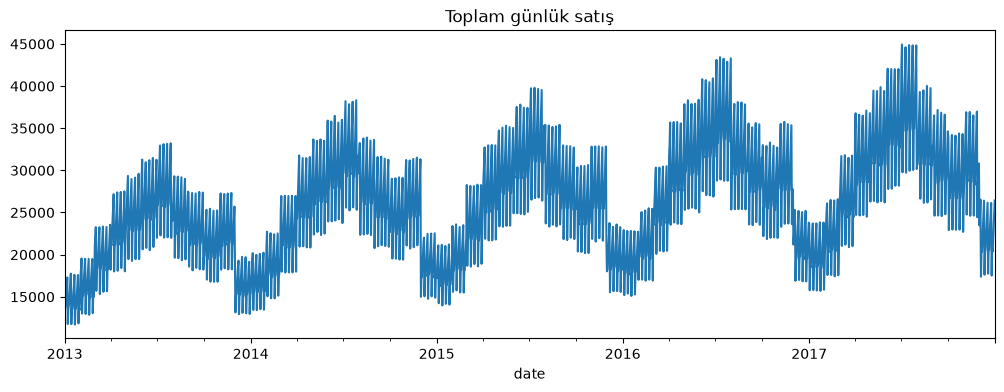

In [8]:
daily = df.groupby("date")["sales"].sum()
daily.plot(figsize=(12, 4), title="Toplam günlük satış")
plt.show()

C:\Users\enisc\AppData\Local\Temp\ipykernel_4124\98373991.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  haftalik = df.groupby(df["date"].dt.dayofweek)["sales"].mean()


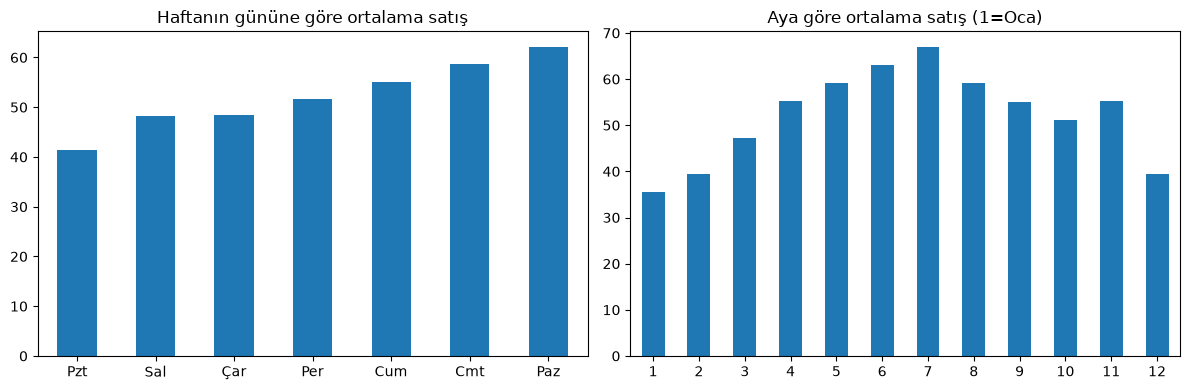

In [10]:
gun_adlari = ["Pzt", "Sal", "Çar", "Per", "Cum", "Cmt", "Paz"]

haftalik = df.groupby(df["date"].dt.dayofweek)["sales"].mean()
haftalik.index = gun_adlari

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
haftalik.plot(kind="bar", ax=axes[0], title="Haftanın gününe göre ortalama satış", rot=0)
df.groupby(df["date"].dt.month)["sales"].mean().plot(kind="bar", ax=axes[1], title="Aya göre ortalama satış (1=Oca)", rot=0)
axes[0].set_xlabel("")
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()